# Chapitre 1 - Cours 1 : penser les systèmes de données, l'exemple des timelines de Twitter

Le chapitre 1 pose le vocabulaire de tout le livre : **fiabilité**, **scalabilité** et
**maintenabilité**. Pour rendre la scalabilité concrète, le livre décrit la charge de
Twitter et la façon dont l'entreprise construit les timelines (fils d'accueil) de ses
utilisateurs. Ce notebook couvre la section *Thinking About Data Systems* et la
sous-section *Describing Load* de la section *Scalability*.

**Plan.**

- Penser les systèmes de données : des briques assemblées en un système composite.
1. Le schéma relationnel et la requête de timeline, exécutés sur SQLite.
2. Les ordres de grandeur de la charge, et ce qu'ils coûtent.
3. Le fan-out à l'écriture : des timelines matérialisées.
4. La loi de puissance des abonnés et le problème des célébrités.
5. L'approche hybride et le choix d'un seuil.
6. Décrire la charge : paramètres, moyennes et cas extrêmes.

In [1]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## Penser les systèmes de données (section *Thinking About Data Systems*)

On range traditionnellement les outils en catégories bien séparées : bases de données,
caches, index de recherche, files de messages. Le livre défend une autre lecture : ces
catégories se brouillent (Redis sert de base et de file, Kafka de file durable qui
ressemble à une base), et surtout une application réelle en **assemble plusieurs**. Le
code applicatif devient alors le chef d'orchestre d'un **système de données composite**,
dont il doit garantir la cohérence : quand le cache est-il invalidé ? l'index est-il à
jour ? que se passe-t-il si l'un des composants tombe ?

Le schéma ci-dessous dessine une telle architecture. Le développeur qui l'écrit est
devenu, qu'il le veuille ou non, un **concepteur de système de données** : l'API qu'il
expose cache les détails, mais c'est à lui de garantir les propriétés de l'ensemble.

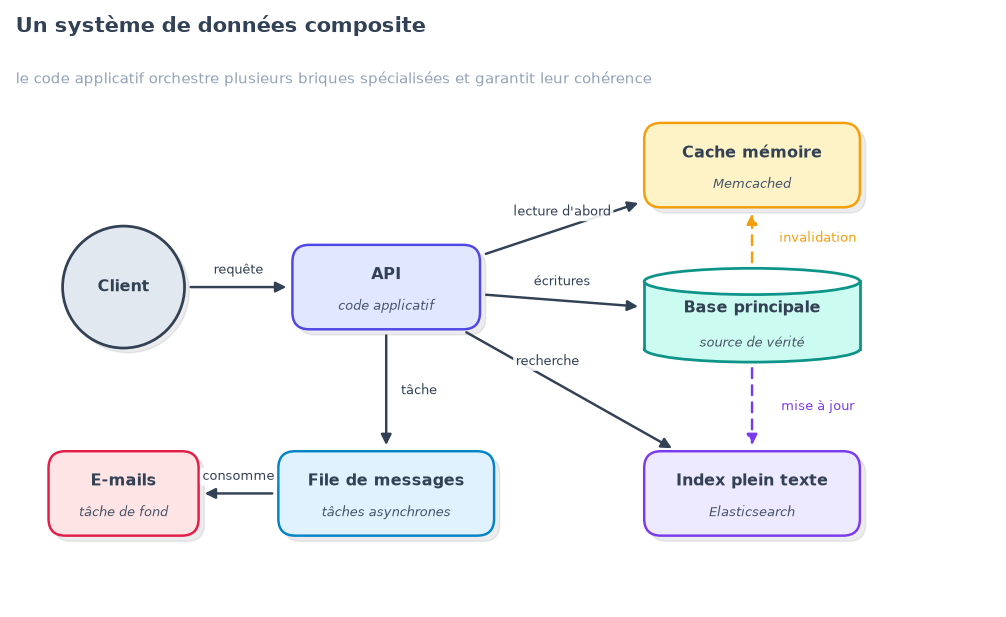

In [2]:
d = Diagram(10.5, 5.4, title="Un système de données composite",
            subtitle="le code applicatif orchestre plusieurs briques spécialisées et garantit leur cohérence")
d.box("client", 1.2, 3.4, "Client", kind="user", w=1.3, color=SLATE)
d.box("api", 4.0, 3.4, "API", sub="code applicatif", color=INDIGO, w=2.0)
d.box("cache", 7.9, 4.7, "Cache mémoire", sub="Memcached", color=AMBER, w=2.3)
d.box("db", 7.9, 3.1, "Base principale", sub="source de vérité", color=TEAL, kind="db", w=2.3, h=1.0)
d.box("idx", 7.9, 1.2, "Index plein texte", sub="Elasticsearch", color=VIOLET, w=2.3)
d.box("q", 4.0, 1.2, "File de messages", sub="tâches asynchrones", color=SKY, w=2.3)
d.box("mail", 1.2, 1.2, "E-mails", sub="tâche de fond", color=ROSE, w=1.6)
d.arrow("client", "api", "requête")
d.arrow("api", "cache", "lecture d'abord")
d.arrow("api", "db", "écritures", label_offset=(0, 0.2))
d.arrow("api", "idx", "recherche", label_pos=0.4)
d.arrow("db", "cache", "invalidation", style="dashed", color=AMBER, label_offset=(0.7, 0))
d.arrow("db", "idx", "mise à jour", style="dashed", color=VIOLET, label_offset=(0.7, 0))
d.arrow("api", "q", "tâche", label_offset=(0.35, 0))
d.arrow("q", "mail", "consomme")
d.show()

Les trois préoccupations qui structurent le chapitre se posent dès ce schéma :

- **fiabilité** : le système doit continuer à fonctionner correctement quand quelque
  chose se passe mal (panne d'un serveur, bogue, erreur humaine) ;
- **scalabilité** : quand la charge augmente (plus d'utilisateurs, plus de données), il
  doit exister des moyens raisonnables de suivre ;
- **maintenabilité** : au fil des années, de nombreuses personnes devront le faire
  tourner et le modifier, il faut que ce soit possible et productif.

> **À retenir.** Une application « gourmande en données » assemble des briques
> spécialisées (base, cache, index, file) ; celui qui les assemble conçoit un système
> de données et répond de sa fiabilité, de sa scalabilité et de sa maintenabilité.

## 1. Le schéma relationnel et la requête de timeline (section *Describing Load*)

**Le problème.** Chaque utilisateur doit voir sa **timeline d'accueil** : les messages
récents des comptes qu'il suit, du plus récent au plus ancien. Le modèle le plus direct
tient en trois tables : `users`, `posts` (avec l'identifiant de l'auteur et un
horodatage) et `follows` (une ligne par relation « A suit B »). La timeline est alors une
**jointure** : trouver les comptes suivis, leurs messages récents, trier et garder les
premiers.

Construisons ce schéma sur SQLite avec un graphe social synthétique de 5 000 comptes
(fonction `rq.social_graph` : la popularité suit une loi de puissance, nous y
reviendrons en section 4).

In [3]:
N_USERS = 5_000
follower, followee = rq.social_graph(N_USERS, mean_follows=50, alpha=1.2, seed=1)
n_followers, n_following = rq.degree_counts(follower, followee, N_USERS)

con = sqlite3.connect(":memory:")
con.executescript("""
CREATE TABLE users   (id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE posts   (id INTEGER PRIMARY KEY, sender_id INTEGER, timestamp REAL, text TEXT);
CREATE TABLE follows (follower_id INTEGER, followee_id INTEGER, PRIMARY KEY (follower_id, followee_id));
CREATE INDEX posts_by_sender ON posts (sender_id, timestamp);
""")
con.executemany("INSERT INTO users VALUES (?, ?)", ((i, f"user{i}") for i in range(N_USERS)))
con.executemany("INSERT INTO follows VALUES (?, ?)", zip(follower.tolist(), followee.tolist()))

# 40 messages par compte en moyenne, sur 30 jours, auteurs tirés uniformément
N_POSTS = 200_000
sender = rng.integers(0, N_USERS, N_POSTS)
ts = np.sort(rng.uniform(0, 30 * 86400, N_POSTS))
con.executemany("INSERT INTO posts VALUES (?, ?, ?, ?)",
                ((i, int(s), float(t), f"message {i}") for i, (s, t) in enumerate(zip(sender, ts))))
con.commit()
pd.DataFrame({"table": ["users", "posts", "follows"],
              "lignes": [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ["users", "posts", "follows"]]})

,table,lignes
0,users,5000
1,posts,200000
2,follows,205819


La requête de timeline, adaptée de celle du livre (avec une limite de 50 messages au
lieu de 1 000 pour notre petit jeu de données) :

In [4]:
TIMELINE_SQL = """
SELECT posts.id, posts.sender_id, posts.timestamp, users.name
  FROM posts
  JOIN follows ON posts.sender_id = follows.followee_id
  JOIN users   ON posts.sender_id = users.id
 WHERE follows.follower_id = ?
 ORDER BY posts.timestamp DESC
 LIMIT 50
"""
for row in con.execute("EXPLAIN QUERY PLAN " + TIMELINE_SQL, (0,)):
    print(row[-1])

SEARCH follows USING COVERING INDEX sqlite_autoindex_follows_1 (follower_id=?)
SEARCH users USING INTEGER PRIMARY KEY (rowid=?)
SEARCH posts USING COVERING INDEX posts_by_sender (sender_id=?)
USE TEMP B-TREE FOR ORDER BY


Le plan de requête confirme l'intuition du livre : SQLite parcourt la liste des comptes
suivis (clé primaire de `follows`), va chercher pour chacun ses messages via l'index
`posts_by_sender`, puis **trie** l'ensemble dans une structure temporaire (`USE TEMP
B-TREE FOR ORDER BY`). Le travail est donc proportionnel au nombre de comptes suivis et à
leur activité, et non à la taille de la timeline demandée. Mesurons le temps de la
requête pour des utilisateurs qui suivent de quelques comptes à plusieurs centaines.

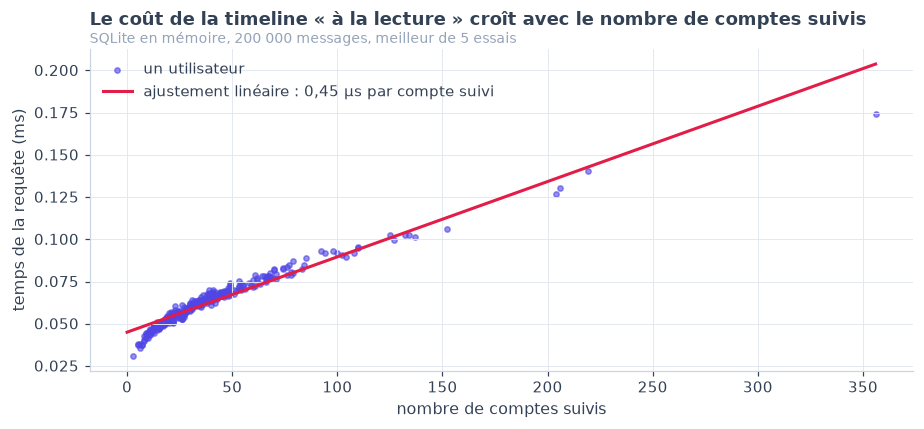

In [5]:
def time_query(sql, arg, repeat=5):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter()
        con.execute(sql, (arg,)).fetchall()
        best = min(best, time.perf_counter() - t0)
    return best * 1e3

sample_users = rng.choice(N_USERS, 300, replace=False)
mes = pd.DataFrame({"suivis": n_following[sample_users],
                    "ms": [time_query(TIMELINE_SQL, int(u)) for u in sample_users]})
coef = np.polyfit(mes.suivis, mes.ms, 1)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(mes.suivis, mes.ms, s=12, color=INDIGO, alpha=0.6, label="un utilisateur")
xs = np.linspace(0, mes.suivis.max(), 50)
ax.plot(xs, np.polyval(coef, xs), color=ROSE, label=f"ajustement linéaire : {coef[0] * 1e3:.2f} µs par compte suivi".replace(".", ","))
ax.set_xlabel("nombre de comptes suivis")
ax.set_ylabel("temps de la requête (ms)")
ax.set_title("Le coût de la timeline « à la lecture » croît avec le nombre de comptes suivis")
subtitle(ax, f"SQLite en mémoire, {fmt(N_POSTS)} messages, meilleur de 5 essais")
ax.legend()
plt.tight_layout(); plt.show()

Le coût est à peu près **linéaire** dans le nombre de comptes suivis : chaque compte
suivi ajoute une recherche dans l'index des messages et des lignes à trier. Sur une
machine et quelques milliers de comptes, c'est rapide. Le problème n'est pas une requête,
c'est leur **nombre** : passons aux ordres de grandeur.

> **À retenir.** La timeline relationnelle est une jointure suivie d'un tri. Son coût
> est proportionnel au nombre de comptes suivis : c'est un calcul **à la lecture**,
> refait à chaque consultation.